# Management-Intensity Sensitivity Analysis

In [ ]:
import warnings
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from joblib import Parallel, delayed
from tqdm import tqdm

sys.path.append('../..')  # repo root, so `scripts` is importable
from scripts.forecasting_helpers import (
    FEATURES, CATEGORICAL_FEATURES, NUMERIC_FEATURES, TARGETS,
    load_xgboost_hyperparameters, get_model,
)

warnings.filterwarnings('ignore', category=FutureWarning)
pd.options.mode.chained_assignment = None
np.random.seed(35)

In [ ]:
# --- Configuration ---

RCP_SCENARIO = "RCP45"   # Options: "RCP26", "RCP45", "RCP85"; uses this RCP's changing climate inputs
N_SEEDS      = 20
RANDOMSEED   = 35
N_JOBS       = 8

FILE_PATH            = Path(f'../../data/preprocessed/final_nfi_ch2018_merged/NFI_with_Climate_Averages_{RCP_SCENARIO}.csv')
HYPERPARAMETERS_FILE = Path('../../data/hyperparameters/nfi123/best_params.json')
OUTPUT_DIR           = Path('../../figures/management_sensitivity')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

MANAGEMENT_SCENARIOS = {
    1.0: 'Managed',
    2.0: 'Rarely managed',
    3.0: 'Unmanaged'
}
SCENARIO_COLORS = {
    1.0: '#d73027',
    2.0: '#4575b4',
    3.0: '#1a9850'
}

In [ ]:
# --- Helper functions ---

def run_scenario_seed(seed, train_data, scenario_prediction_data, final_feature_cols, hyperparameters):
    """Train models on observed data; run iterative prediction on counterfactual scenario data.

    The iterative prediction is batched across plots: at every time step, all plots that still
    have a step to take are predicted in a single call. Plots are independent of each other
    (the only dependency is within a plot, where a year's prediction feeds the next year's
    BASFPH/HWSW_prop features), so this is numerically identical to a per-plot, per-row loop
    while drastically cutting the number of model.predict() calls.
    """
    X_train = train_data[final_feature_cols]
    y_train = train_data[TARGETS]

    model_basfph = get_model('BASFPH_next_INVNR', seed, hyperparameters)
    model_basfph.fit(X_train, y_train['BASFPH_next_INVNR'])

    model_hwsw = get_model('HWSW_prop_next_INVNR', seed, hyperparameters)
    model_hwsw.fit(X_train, y_train['HWSW_prop_next_INVNR'])

    # Feature matrix aligned row-for-row with the scenario data; BASFPH/HWSW_prop are both
    # feature columns, so updating them in place feeds the next step.
    feat = scenario_prediction_data[final_feature_cols].to_numpy(dtype=np.float64).copy()
    col_basfph = final_feature_cols.index('BASFPH')
    col_hwsw   = final_feature_cols.index('HWSW_prop')

    invnr_values   = scenario_prediction_data['INVNR'].to_numpy()
    basfph_present = scenario_prediction_data['BASFPH'].notna().to_numpy()

    # For each plot, build the sequence of row positions from its valid start onward.
    plot_seqs = []
    max_steps = 0
    for positions in scenario_prediction_data.groupby('CLNR').indices.values():
        mask = (invnr_values[positions] == 550) & basfph_present[positions]
        if not mask.any():
            continue  # No valid starting point
        start = int(np.argmax(mask))  # first row where INVNR == 550 and BASFPH not NaN
        seq = positions[start:]
        if len(seq) < 2:
            continue  # Nothing to predict forward
        plot_seqs.append(seq)
        max_steps = max(max_steps, len(seq) - 1)

    # Iterative prediction loop, batched across plots per step.
    for k in range(max_steps):
        cur_pos = np.asarray([seq[k]     for seq in plot_seqs if k + 1 < len(seq)])
        nxt_pos = np.asarray([seq[k + 1] for seq in plot_seqs if k + 1 < len(seq)])
        X_step  = feat[cur_pos]
        feat[nxt_pos, col_basfph] = np.clip(model_basfph.predict(X_step, validate_features=False), 0, 100)
        feat[nxt_pos, col_hwsw]   = np.clip(model_hwsw.predict(X_step, validate_features=False), 0, 1)

    return pd.DataFrame({
        'CLNR':      scenario_prediction_data['CLNR'].to_numpy(),
        'INVNR':     scenario_prediction_data['INVNR'].to_numpy(),
        'INVYR':     scenario_prediction_data['INVYR'].to_numpy(),
        'BASFPH':    feat[:, col_basfph],
        'HWSW_prop': feat[:, col_hwsw],
    })

In [ ]:
# --- Load data and build base OHE (used for training) ---

full_data = pd.read_csv(FILE_PATH)
print(f"Loaded data: {full_data.shape}")

full_data = full_data[(full_data['BASFPH'].isna()) | (full_data['BASFPH'] <= 100)].copy()
full_data = full_data[(full_data['BASFPH_next_INVNR'].isna()) | (full_data['BASFPH_next_INVNR'] <= 100)].copy()

# Tag future rows (originally NaN BASFPH) before any processing
future_rows_mask = full_data['BASFPH'].isna()

# OHE on full dataset → defines the reference feature set for training
full_data_processed = pd.get_dummies(full_data, columns=CATEGORICAL_FEATURES, drop_first=True)

ohe_features       = [c for c in full_data_processed.columns if c.startswith(tuple(cat + '_' for cat in CATEGORICAL_FEATURES))]
FINAL_FEATURE_COLS = NUMERIC_FEATURES + ohe_features
print(f"OHE columns: {ohe_features}")
print(f"Total features: {len(FINAL_FEATURE_COLS)}")

train_data = full_data_processed.dropna(subset=TARGETS).copy()
train_data.dropna(subset=FINAL_FEATURE_COLS, inplace=True)
print(f"Training samples: {len(train_data)}")

# Sorted full dataset for the iterative prediction loop
prediction_data = full_data_processed.sort_values(['CLNR', 'INVYR'], ignore_index=True)

# Map each future inventory round (INVNR) → its mean calendar year.
# The NFI is a rolling inventory: each round spans 4-5 years with different plots
# measured each year. Grouping by INVNR ensures all ~4000 plots in a round are
# averaged together, avoiding the sawtooth from comparing different plot subsets
# across years within a round.
future_invnr_to_year = (
    full_data.loc[future_rows_mask]
    .groupby('INVNR')['INVYR']
    .mean()
    .astype(int)
    .to_dict()
)
print(f"\nInventory round → representative year:")
for invnr, yr in sorted(future_invnr_to_year.items()):
    n = (full_data.loc[future_rows_mask, 'INVNR'] == invnr).sum()
    print(f"  INVNR={invnr}: {yr}  ({n} plots)")

Loaded data: (51872, 34)
OHE columns: ['BEWIRTINT1_2.0', 'BEWIRTINT1_3.0', 'NAISHSTKOMB_2', 'NAISHSTKOMB_3', 'NAISHSTKOMB_4', 'NAISHSTKOMB_5', 'NAISHSTKOMB_6', 'NAISHSTKOMB_7', 'NAISHSTKOMB_8', 'NAISHSTKOMB_9', 'NAISHSTKOMB_10']
Total features: 29
Training samples: 15516

Inventory round → representative year:
  INVNR=650: 2030  (4019 plots)
  INVNR=750: 2039  (4019 plots)
  INVNR=850: 2049  (4019 plots)
  INVNR=950: 2059  (4019 plots)
  INVNR=1050: 2069  (4019 plots)
  INVNR=1150: 2079  (4019 plots)
  INVNR=1250: 2089  (4019 plots)
  INVNR=1350: 2099  (4019 plots)


In [ ]:
# --- Identify BEWIRTINT1 OHE structure ---

bewirt_ohe_cols   = [c for c in ohe_features if c.startswith('BEWIRTINT1_')]
present_cats      = {float(c.split('_')[-1]) for c in bewirt_ohe_cols}
all_cats          = set(full_data['BEWIRTINT1'].dropna().unique())
reference_cat     = all_cats - present_cats

print(f"All BEWIRTINT1 categories: {sorted(all_cats)}")
print(f"OHE columns (non-reference):  {bewirt_ohe_cols}")
print(f"Reference category (dropped by drop_first): {reference_cat}")

def apply_management_scenario(prediction_data_processed, scenario_value, bewirt_cols):
    """Override BEWIRTINT1 OHE columns for all rows to a single counterfactual scenario."""
    df = prediction_data_processed.copy()
    for col in bewirt_cols:
        df[col] = 0
    target_col = f'BEWIRTINT1_{float(scenario_value)}'
    if target_col in df.columns:
        df[target_col] = 1
    # If scenario_value is the reference category, all cols stay 0 — correct for drop_first
    return df

All BEWIRTINT1 categories: [np.float64(1.0), np.float64(2.0), np.float64(3.0)]
OHE columns (non-reference):  ['BEWIRTINT1_2.0', 'BEWIRTINT1_3.0']
Reference category (dropped by drop_first): {np.float64(1.0)}


In [ ]:
# --- Run iterative prediction for each management scenario ---

hyperparameters = load_xgboost_hyperparameters(HYPERPARAMETERS_FILE)
master_rng      = np.random.RandomState(RANDOMSEED)
SEEDS           = master_rng.randint(0, 100000, N_SEEDS)

scenario_results = {}

for scenario_value, scenario_label in MANAGEMENT_SCENARIOS.items():
    print(f"\n--- Scenario: {scenario_label} (BEWIRTINT1 = {scenario_value}) ---")

    scenario_pred_data = apply_management_scenario(prediction_data, scenario_value, bewirt_ohe_cols)

    seed_outputs = Parallel(n_jobs=N_JOBS, prefer='threads')(
        delayed(run_scenario_seed)(
            seed, train_data, scenario_pred_data, FINAL_FEATURE_COLS, hyperparameters
        )
        for seed in tqdm(SEEDS, desc=scenario_label)
    )

    scenario_results[scenario_value] = seed_outputs
    print(f"  Completed {len(seed_outputs)} seeds.")


--- Scenario: Managed (BEWIRTINT1 = 1.0) ---


Managed: 100%|██████████| 20/20 [00:03<00:00,  5.89it/s]


  Completed 20 seeds.

--- Scenario: Rarely managed (BEWIRTINT1 = 2.0) ---


Rarely managed: 100%|██████████| 20/20 [00:02<00:00,  9.89it/s]


  Completed 20 seeds.

--- Scenario: Unmanaged (BEWIRTINT1 = 3.0) ---


Unmanaged: 100%|██████████| 20/20 [00:02<00:00,  9.75it/s]


  Completed 20 seeds.


In [ ]:
# --- Aggregate future predictions across seeds ---

def aggregate_scenario(seed_outputs, target_col, invnr_to_year):
    """
    For each seed, compute the mean of target_col across all plots per INVNR round.
    Groups by INVNR (not INVYR) so all plots in a rolling-inventory round are averaged
    together. The INVNR index is then remapped to the representative calendar year.
    Returns a DataFrame: index=Year, columns=[mean, std, q05, q95].
    """
    seed_means = []
    for df in seed_outputs:
        future = df[df['INVNR'].isin(invnr_to_year.keys())]
        seed_means.append(future.groupby('INVNR')[target_col].mean())

    stacked = pd.DataFrame(seed_means)   # shape: (N_SEEDS, n_inventory_rounds)
    result = pd.DataFrame({
        'mean': stacked.mean(axis=0),
        'std':  stacked.std(axis=0),
        'q05':  stacked.quantile(0.05, axis=0),
        'q95':  stacked.quantile(0.95, axis=0),
    })
    result.index = result.index.map(invnr_to_year)
    result.index.name = 'Year'
    return result

aggregated = {}
for scenario_value, seed_outputs in scenario_results.items():
    aggregated[scenario_value] = {
        'BASFPH':    aggregate_scenario(seed_outputs, 'BASFPH',    future_invnr_to_year),
        'HWSW_prop': aggregate_scenario(seed_outputs, 'HWSW_prop', future_invnr_to_year),
    }

print("Aggregation complete.")
for sv, sl in MANAGEMENT_SCENARIOS.items():
    last = aggregated[sv]['BASFPH']['mean'].iloc[-1]
    print(f"  {sl}: final mean BASFPH = {last:.2f} m²/ha")

Aggregation complete.
  Managed: final mean BASFPH = 36.01 m²/ha
  Rarely managed: final mean BASFPH = 37.31 m²/ha
  Unmanaged: final mean BASFPH = 36.58 m²/ha


Saved: ../../figures/management_sensitivity/management_sensitivity_RCP45.png


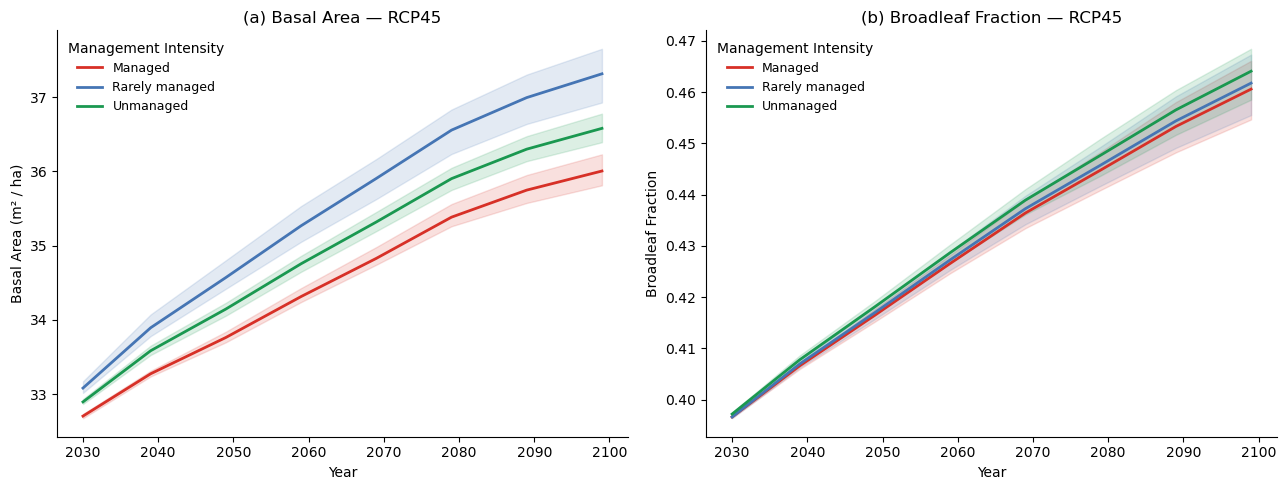

In [ ]:
# --- Plot: BASFPH and HWSW_prop trajectories by management scenario ---

target_configs = [
    {
        'key':    'BASFPH',
        'ylabel': 'Basal Area (m² / ha)',
        'title':  'Basal Area',
        'panel':  '(a)',
    },
    {
        'key':    'HWSW_prop',
        'ylabel': 'Broadleaf Fraction',
        'title':  'Broadleaf Fraction',
        'panel':  '(b)',
    },
]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, cfg in zip(axes, target_configs):
    for scenario_value, scenario_label in MANAGEMENT_SCENARIOS.items():
        color = SCENARIO_COLORS[scenario_value]
        agg   = aggregated[scenario_value][cfg['key']]
        years = agg.index
        ax.plot(years, agg['mean'], color=color, label=scenario_label, linewidth=2)
        ax.fill_between(years, agg['q05'], agg['q95'], color=color, alpha=0.15)

    ax.set_xlabel('Year')
    ax.set_ylabel(cfg['ylabel'])
    ax.set_title(f"{cfg['panel']} {cfg['title']} — {RCP_SCENARIO}")
    ax.legend(title='Management Intensity', frameon=False, fontsize=9)
    ax.spines[['top', 'right']].set_visible(False)

plt.tight_layout()
fname = f'management_sensitivity_{RCP_SCENARIO}.png'
fig.savefig(OUTPUT_DIR / fname, dpi=300, bbox_inches='tight')
print(f"Saved: {OUTPUT_DIR / fname}")
plt.show()

Saved: ../../figures/management_sensitivity/management_sensitivity_delta_RCP45.png


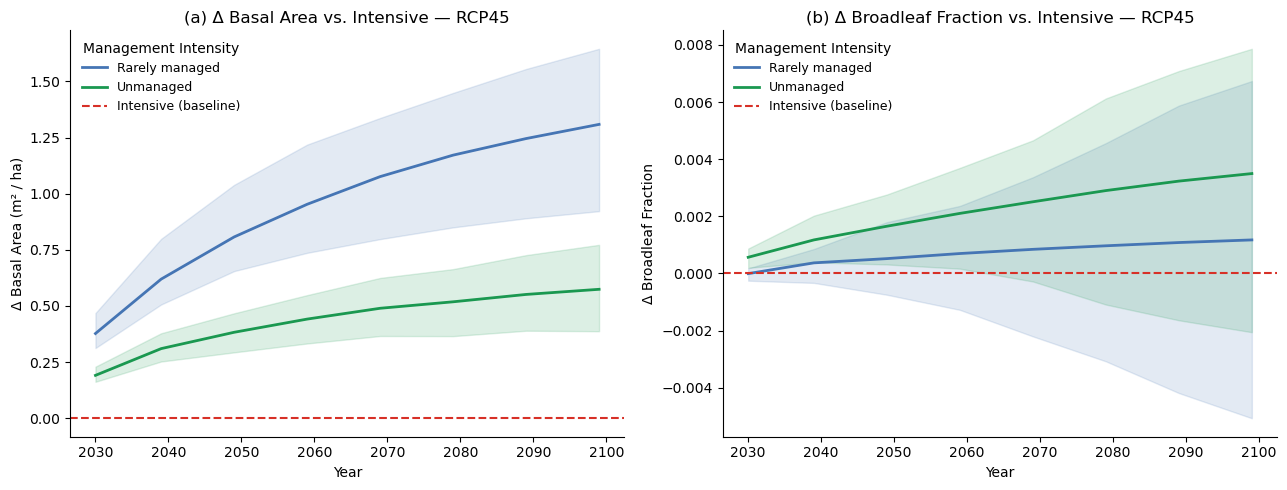

In [ ]:
# --- Difference plot: scenario contrast relative to Intensive baseline ---

baseline = 1.0   # Intensive as reference

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, cfg in zip(axes, target_configs):
    base_mean = aggregated[baseline][cfg['key']]['mean']
    for scenario_value, scenario_label in MANAGEMENT_SCENARIOS.items():
        if scenario_value == baseline:
            continue
        color    = SCENARIO_COLORS[scenario_value]
        agg      = aggregated[scenario_value][cfg['key']]
        delta    = agg['mean'] - base_mean
        ax.plot(delta.index, delta, color=color, label=scenario_label, linewidth=2)
        ax.fill_between(delta.index,
                        agg['q05'] - base_mean,
                        agg['q95'] - base_mean,
                        color=color, alpha=0.15)

    ax.axhline(0, color=SCENARIO_COLORS[baseline], linewidth=1.5,
               linestyle='--', label='Intensive (baseline)')
    ax.set_xlabel('Year')
    ax.set_ylabel(f'Δ {cfg["ylabel"]}')
    ax.set_title(f"{cfg['panel']} Δ {cfg['title']} vs. Intensive — {RCP_SCENARIO}")
    ax.legend(title='Management Intensity', frameon=False, fontsize=9)
    ax.spines[['top', 'right']].set_visible(False)

plt.tight_layout()
fname_diff = f'management_sensitivity_delta_{RCP_SCENARIO}.png'
fig.savefig(OUTPUT_DIR / fname_diff, dpi=300, bbox_inches='tight')
print(f"Saved: {OUTPUT_DIR / fname_diff}")
plt.show()

In [ ]:
# --- Summary table: mean ± std at key years ---

summary_rows = []
for scenario_value, scenario_label in MANAGEMENT_SCENARIOS.items():
    for target_key in ['BASFPH', 'HWSW_prop']:
        agg = aggregated[scenario_value][target_key]
        for year in agg.index:
            summary_rows.append({
                'Scenario':   scenario_label,
                'BEWIRTINT1': scenario_value,
                'Target':     target_key,
                'Year':       year,
                'Mean':       agg.loc[year, 'mean'],
                'Std':        agg.loc[year, 'std'],
                'Q05':        agg.loc[year, 'q05'],
                'Q95':        agg.loc[year, 'q95'],
            })

summary_df = pd.DataFrame(summary_rows)

final_year = max(future_invnr_to_year.values())
print(f"\nSummary at final year ({final_year}):")
print(
    summary_df[summary_df['Year'] == final_year]
    [['Scenario', 'Target', 'Mean', 'Std', 'Q05', 'Q95']]
    .round(3)
    .to_string(index=False)
)

summary_df.to_csv(OUTPUT_DIR / f'management_sensitivity_summary_{RCP_SCENARIO}.csv', index=False, float_format='%.4f')
print(f"\nFull summary saved to {OUTPUT_DIR / f'management_sensitivity_summary_{RCP_SCENARIO}.csv'}")


Summary at final year (2099):
      Scenario    Target   Mean   Std    Q05    Q95
       Managed    BASFPH 36.005 0.142 35.813 36.229
       Managed HWSW_prop  0.461 0.004  0.455  0.466
Rarely managed    BASFPH 37.314 0.232 36.927 37.650
Rarely managed HWSW_prop  0.462 0.004  0.456  0.467
     Unmanaged    BASFPH 36.579 0.129 36.393 36.777
     Unmanaged HWSW_prop  0.464 0.003  0.459  0.468

Full summary saved to ../../figures/management_sensitivity/management_sensitivity_summary_RCP45.csv
